       Measurements  Distance_mm  Sample  RSSI_dBm
0     0dBm_messung1       1000.0       1       NaN
1     0dBm_messung1       1000.0       2     -60.0
2     0dBm_messung1       1000.0       3     -60.0
3     0dBm_messung1       1000.0       4     -60.0
4     0dBm_messung1       1000.0       5     -60.0
...             ...          ...     ...       ...
4795  0dBm_messung5       4000.0     960       NaN
4796  0dBm_messung5       4000.0     961       NaN
4797  0dBm_messung5       4000.0     962       NaN
4798  0dBm_messung5       4000.0     963       NaN
4799  0dBm_messung5       4000.0     964       NaN

[4800 rows x 4 columns]


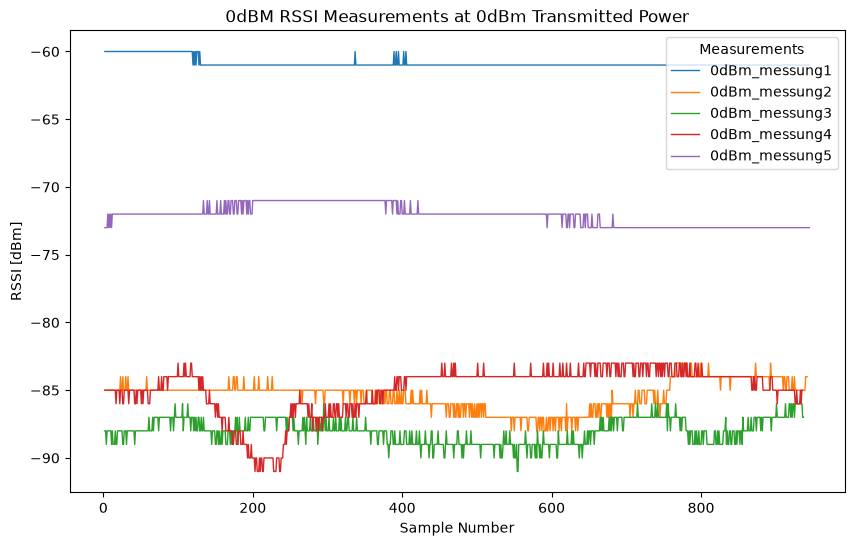

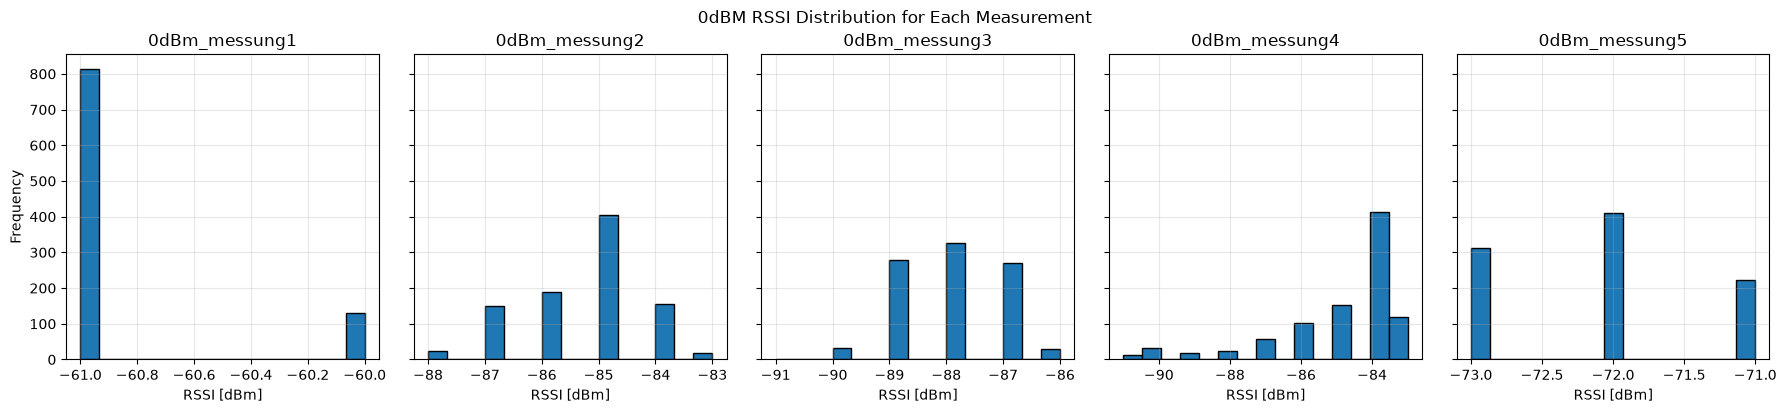

In [ ]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
from pathlib import Path
import re

data_dir = Path("./Measurements")
image_dir = Path("../Reports/images")
files = sorted(data_dir.glob("0dBm_messung*.txt"))

def save_plot(fig, title):
    filename = re.sub(r"[^\w\s-]", "", title)
    filename = re.sub(r"[\s-]+", "_", filename).strip("_")
    fig.savefig(image_dir / f"{filename}.png", dpi=300, bbox_inches="tight")

measurements1 = [] 

for file in files:
    df = pd.read_csv(file, header=None, names=["raw"], dtype=str)

    df["RSSI_dBm"] = (
        df["raw"]
        .str.extract(r"RX-RSSI=(-?\d+(?:\.\d+)?)", expand=False)
        .astype(float)
    )
    distance = df["raw"].str.extract(
        r"(?<!\d)(\d+(?:\.\d+)?)\s*mm\b", expand=False
    ).dropna()

    if distance.empty:
         df["Distance_mm"] = -1
    else:
        df["Distance_mm"] = float(distance.iloc[0])

    df["Sample"] = np.arange(1, len(df) + 1)
    df["Measurements"] = file.stem 

    measurements1.append(df[["Measurements","Distance_mm", "Sample", "RSSI_dBm"]])


data = pd.concat(measurements1, ignore_index=True)
print(data)

summary1 = data.groupby("Measurements")["RSSI_dBm"].agg(
    sampels="count", 
    mean="mean",
    median="median", 
    std="std", 
    min="min",
    max ="max",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
)
summary1["packet_loss"] = (1 - (summary1["sampels"] / 1000)) * 100
summary1["distance_mm"] = data.groupby("Measurements")["Distance_mm"].first()
summary1 = summary.sort_values("distance_mm")
summary1["range"] = summary1["max"] - summary1["min"]
summary1["coefficient_of_variation"] = summary1["std"] / summary1["mean"].abs() 
summary1.round(2) 

title = "0dBM RSSI Measurements at 0dBm Transmitted Power"

fig = plt.figure(figsize=(10, 6))
for name, group in data.groupby("Measurements"):
    plt.plot(
        group["Sample"],
        group["RSSI_dBm"],
        label=name,
        linewidth=1
    )

plt.title(title)
plt.xlabel("Sample Number")
plt.ylabel("RSSI [dBm]")
plt.legend(title="Measurements")
save_plot(fig, title)
plt.show()

title = "0dBM RSSI Distribution for Each Measurement"

fig, axes = plt.subplots(1, len(files), figsize=(18, 4), sharey=True)

for ax, (name, group) in zip(axes, data.groupby("Measurements")):
    ax.hist(group["RSSI_dBm"], bins=15, edgecolor="black")
    ax.set_title(name)
    ax.set_xlabel("RSSI [dBm]")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Frequency")
plt.tight_layout()
plt.suptitle(title, y=1.02)
save_plot(fig, title)
plt.show()

fig, ax1 = plt.subplots(figsize=(10, 6))

signal_strength = ax1.plot(
    summary1["distance_mm"],
    summary1["mean"],
    color="blue",
    marker="o",
    linewidth=2,
    label="Mean RSSI"
)

title = "0dBM Mean RSSI and Packet Loss Across Measurements"

ax1.set_xlabel("Distance [mm]")
ax1.set_ylabel("Average RSSI [dBm]", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.grid(True, alpha=0.3)


ax2 = ax1.twinx()
packet_loss = ax2.plot(
    summary1["distance_mm"],
    summary1["packet_loss"],
    color="red",
    marker="x",
    linewidth=2,
    label="Packet Loss"
)

ax2.set_ylabel("Packet Loss [%]", color="red")
ax2.tick_params(axis="y", labelcolor="red")

lines = signal_strength + packet_loss 
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="best")
plt.tight_layout()
plt.title(title)
save_plot(fig, title)
plt.show()

print(summary1)

In [ ]:
data_dir = Path("./Measurements")
image_dir = Path("../Reports/images")
files = sorted(data_dir.glob("-40dBm_messung*.txt"))

measurements2 = [] 

for file in files:
    df = pd.read_csv(file, header=None, names=["raw"], dtype=str)

    df["RSSI_dBm"] = (
        df["raw"]
        .str.extract(r"RX-RSSI=(-?\d+(?:\.\d+)?)", expand=False)
        .astype(float)
    )
    distance = df["raw"].str.extract(
        r"(?<!\d)(\d+(?:\.\d+)?)\s*mm\b", expand=False
    ).dropna()
    if distance.empty:
         df["Distance_mm"] = -1
    else:
        df["Distance_mm"] = float(distance.iloc[0])

    df["Sample"] = np.arange(1, len(df) + 1)
    df["Measurements"] = file.stem 

    measurements2.append(df[["Measurements","Distance_mm", "Sample", "RSSI_dBm"]])


data2 = pd.concat(measurements2, ignore_index=True)
print(data2)



summary2 = data2.groupby("Measurements")["RSSI_dBm"].agg(
    sampels="count", 
    mean="mean",
    median="median", 
    std="std", 
    min="min",
    max ="max",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
)
summary2["packet_loss"] =( 1 - (summary2["sampels"] / 1000)) * 100
summary2["distance_mm"] = data2.groupby("Measurements")["Distance_mm"].first()
summary2 = summary2.sort_values("distance_mm")
summary2["range"] = summary2["max"] - summary2["min"]
summary2["coefficient_of_variation"] = summary2["std"] / summary2["mean"].abs() 
summary2.round(2) 

         Measurements  Distance_mm  Sample  RSSI_dBm
0     -40dBm_messung1         10.0       1       NaN
1     -40dBm_messung1         10.0       2       NaN
2     -40dBm_messung1         10.0       3       NaN
3     -40dBm_messung1         10.0       4     -61.0
4     -40dBm_messung1         10.0       5     -62.0
...               ...          ...     ...       ...
5343  -40dBm_messung9        300.0     954       NaN
5344  -40dBm_messung9        300.0     955       NaN
5345  -40dBm_messung9        300.0     956       NaN
5346  -40dBm_messung9        300.0     957       NaN
5347  -40dBm_messung9        300.0     958       NaN

[5348 rows x 4 columns]


,sampels,mean,median,std,min,max,q25,q75,packet_loss,distance_mm,range,coefficient_of_variation
Measurements,,,,,,,,,,,,
-40dBm_messung1,945,-61.79,-62.0,0.41,-62.0,-61.0,-62.0,-62.0,5.5,10.0,1.0,0.01
-40dBm_messung7,934,-79.02,-79.0,0.17,-80.0,-78.0,-79.0,-79.0,6.6,100.0,2.0,0.00
-40dBm_messung8,937,-80.09,-80.0,0.30,-81.0,-78.0,-80.0,-80.0,6.3,200.0,3.0,0.00
-40dBm_messung9,937,-83.01,-83.0,0.20,-84.0,-82.0,-83.0,-83.0,6.3,300.0,2.0,0.00
-40dBm_messung10,132,-93.09,-93.0,0.67,-95.0,-92.0,-94.0,-93.0,86.8,400.0,3.0,0.01
-40dBm_messung5,60,-93.47,-93.0,0.72,-95.0,-92.0,-94.0,-93.0,94.0,500.0,3.0,0.01
-40dBm_messung6,60,-93.47,-93.0,0.72,-95.0,-92.0,-94.0,-93.0,94.0,500.0,3.0,0.01
-40dBm_messung2,899,-87.78,-88.0,0.53,-89.0,-86.0,-88.0,-87.0,10.1,500.0,3.0,0.01
-40dBm_messung4,59,-93.47,-94.0,0.63,-95.0,-92.0,-94.0,-93.0,94.1,700.0,3.0,0.01


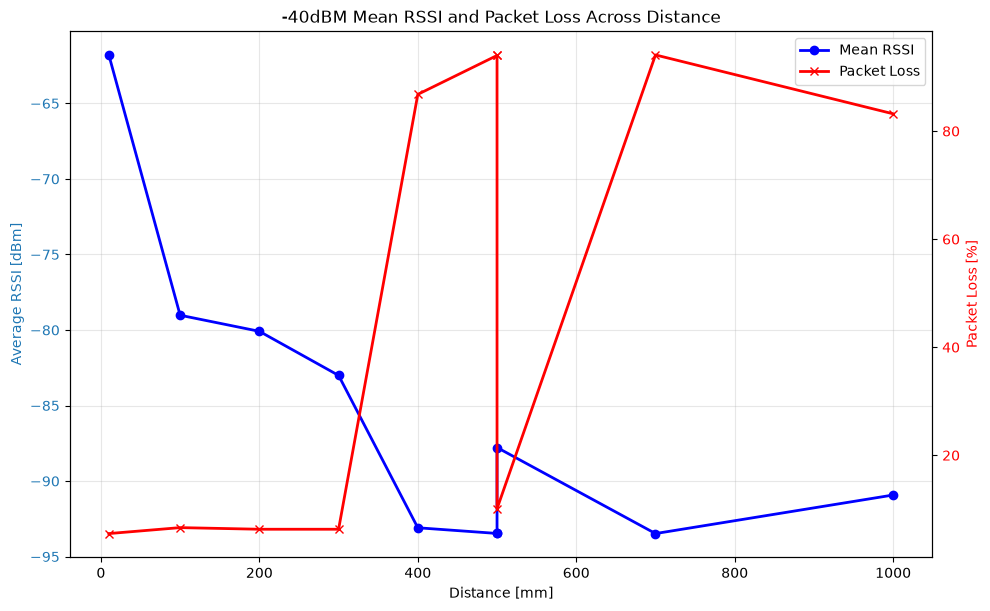

In [ ]:
title = "-40dBM Mean RSSI and Packet Loss Across Distance"

fig, ax1 = plt.subplots(figsize=(10, 6))

signal_strength = ax1.plot(
    summary2["distance_mm"],
    summary2["mean"],
    color="blue",
    marker="o",
    linewidth=2,
    label="Mean RSSI"
)

ax1.set_xlabel("Distance [mm]")
ax1.set_ylabel("Average RSSI [dBm]", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.grid(True, alpha=0.3)


ax2 = ax1.twinx()
packet_loss = ax2.plot(
    summary2["distance_mm"],
    summary2["packet_loss"],
    color="red",
    marker="x",
    linewidth=2,
    label="Packet Loss"
)

ax2.set_ylabel("Packet Loss [%]", color="red")
ax2.tick_params(axis="y", labelcolor="red")

lines = signal_strength + packet_loss 
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="best")
plt.tight_layout()
plt.title(title)
save_plot(fig, title)
plt.show()
save_plot(fig, title)

In [ ]:
% Raw-samples plot for the -40 dBm measurements (needs `data` and `image_dir` from cell 2 above)
title = "40dBM RSSI Measurements at -40dBm Transmitted Power"

dist = data.groupby("Measurements")["Distance_mm"].first()

fig = plt.figure(figsize=(10, 6))
for name in dist.sort_values().index:
    group = data[data["Measurements"] == name]
    plt.plot(
        group["Sample"],
        group["RSSI_dBm"],
        label=f"{name} ({dist[name]:g}mm)",
        linewidth=1
    )

plt.title(title)
plt.xlabel("Sample Number")
plt.ylabel("RSSI [dBm]")
plt.legend(title="Measurements")
plt.grid(True, alpha=0.3)
fig.savefig(image_dir / "40dBM_RSSI_Measurements_at_-40dBm_Transmitted_Power.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# --- Radio mode comparison: IEEE 802.15.4 250 kbit/s data from putty.log.txt (repo root) ---
# Structure per burst: [distance marker, fails as command] + print_rxstart_rx + 1000 RX lines + "Number of packets: N"
text = Path("../putty.log.txt").read_text()
parts = re.split(r"Number of packets: (\d+)\n", text)
# parts = [P0, N1, P1, N2, P2, ...]; the RX lines of burst i are inside P_{i-1}
bursts = []
for i in range(1, len(parts) // 2 + 1):
    rssi = [float(x) for x in re.findall(r"RX-RSSI=(-?\d+(?:\.\d+)?)", parts[2 * i - 2])]
    bursts.append({"packets": int(parts[2 * i - 1]), "mean_rssi": np.mean(rssi)})
bursts = pd.DataFrame(bursts)
# distances verified from the (partly garbled) operator markers; 2nd run = boards touching, not plotted
bursts["distance_mm"] = [None, 250, 0, 400, 500, 3000, 4000]
bursts = bursts[(bursts["distance_mm"].notna()) & (bursts["distance_mm"] > 0)].reset_index(drop=True)
bursts["packet_loss"] = (1 - bursts["packets"] / 1000) * 100
print(bursts.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(summary["distance_mm"], summary["mean"], color="tab:blue", marker="o", linewidth=1.5, label="BLE 2 Mbit/s")
ax1.plot(bursts["distance_mm"], bursts["mean_rssi"], color="tab:red", marker="s", linewidth=1.5, label="IEEE 802.15.4 250 kbit/s")
ax1.set_xscale("log")
ax1.set_xlabel("Distance [mm]")
ax1.set_ylabel("Mean RSSI [dBm]")
ax1.set_title("Mean RSSI")
ax1.grid(True, alpha=0.3, which="both")
ax1.legend()

ax2.plot(summary["distance_mm"], summary["packet_loss"], color="tab:blue", marker="o", linewidth=1.5, label="BLE 2 Mbit/s")
ax2.plot(bursts["distance_mm"], bursts["packet_loss"], color="tab:red", marker="s", linewidth=1.5, label="IEEE 802.15.4 250 kbit/s")
ax2.set_xscale("log")
ax2.set_xlabel("Distance [mm]")
ax2.set_ylabel("Packet Loss [%]")
ax2.set_title("Packet Loss")
ax2.grid(True, alpha=0.3, which="both")
ax2.legend()

fig.suptitle("Radio Mode Comparison at -40 dBm Transmit Power")
plt.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(image_dir / "40dBM_Radio_Mode_Comparison_RSSI_and_Packet_Loss.png", dpi=300, bbox_inches="tight")
plt.show()